# TP CNN : LeNet-5 pour la reconnaissance des caractères Tifinagh (AMHCD, RGB)

**Master IAA : 2025-2026** — Realisée par Chaymae Al-aissaoui

Ce notebook contient **tout le code** du TP, écrit en **NumPy pur** (propagation avant *et* arrière écrites à la main)



## 1. Configuration et utilitaires

In [26]:
import os
import re
import json
import math
import time
import copy

import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
import matplotlib

import matplotlib.pyplot as plt

DTYPE = np.float32          # précision par défaut (float64 pour la vérification des gradients)


def set_seed(seed=0):
    """Fixe la graine globale NumPy (reproductibilité)."""
    np.random.seed(seed)
    return np.random.default_rng(seed)


def init_weights(shape, fan_in, fan_out, method, rng, dtype=DTYPE):
    """Initialisation des poids.
    - 'xavier' : U(-a, a), a = sqrt(6 / (fan_in + fan_out))
    - 'he'     : N(0, 2 / fan_in)            (adapté à ReLU)
    - 'lecun'  : U(-2.4/fan_in, 2.4/fan_in)  (initialisation du papier original)
    """
    if method == "xavier":
        a = math.sqrt(6.0 / (fan_in + fan_out))
        w = rng.uniform(-a, a, size=shape)
    elif method == "he":
        w = rng.normal(0.0, math.sqrt(2.0 / fan_in), size=shape)
    elif method == "lecun":
        a = 2.4 / fan_in
        w = rng.uniform(-a, a, size=shape)
    else:
        raise ValueError(f"Initialisation inconnue : {method}")
    return w.astype(dtype)

## 2. Couches paramétrables

In [27]:
class Layer:
    """Classe de base : chaque couche a forward/backward et ses paramètres."""
    trainable = False

    def __init__(self, name="layer"):
        self.name = name
        self.params = {}
        self.grads = {}
        self.training = True

    def forward(self, x):
        raise NotImplementedError

    def backward(self, dout):
        raise NotImplementedError

    def n_params(self):
        return int(sum(p.size for p in self.params.values()))

    def __repr__(self):
        return f"{self.__class__.__name__}({self.name})"


class Conv2D(Layer):
    """Convolution 2D (corrélation croisée) vectorisée par im2col.

    Entrée  : (N, C_in, H, W)
    Sortie  : (N, C_out, H_out, W_out),  H_out = (H + 2p - k)//s + 1
    """
    trainable = True

    def __init__(self, in_channels, out_channels, kernel_size=5, stride=1, padding=0,
                 init="xavier", rng=None, dtype=DTYPE, name="conv"):
        super().__init__(name)
        rng = rng if rng is not None else np.random.default_rng(0)
        k = kernel_size
        self.in_channels, self.out_channels = in_channels, out_channels
        self.k, self.s, self.p = k, stride, padding
        self.params["W"] = init_weights((out_channels, in_channels, k, k),
                                        in_channels * k * k, out_channels * k * k,
                                        init, rng, dtype)
        self.params["b"] = np.zeros(out_channels, dtype=dtype)

    def forward(self, x):
        N, C, H, W = x.shape
        k, s, p = self.k, self.s, self.p
        xp = np.pad(x, ((0, 0), (0, 0), (p, p), (p, p))) if p > 0 else x
        win = sliding_window_view(xp, (k, k), axis=(2, 3))[:, :, ::s, ::s]   # N,C,Ho,Wo,k,k
        Ho, Wo = win.shape[2], win.shape[3]
        cols = win.transpose(0, 2, 3, 1, 4, 5).reshape(N * Ho * Wo, C * k * k)
        Wm = self.params["W"].reshape(self.out_channels, -1)
        out = cols @ Wm.T + self.params["b"]
        out = out.reshape(N, Ho, Wo, self.out_channels).transpose(0, 3, 1, 2)
        self._cache = (cols, x.shape, xp.shape, Ho, Wo)
        return np.ascontiguousarray(out)

    def backward(self, dout):
        cols, xshape, xpshape, Ho, Wo = self._cache
        N, C = xshape[0], xshape[1]
        k, s, p = self.k, self.s, self.p
        F = self.out_channels
        dflat = dout.transpose(0, 2, 3, 1).reshape(-1, F)
        self.grads["W"] = (dflat.T @ cols).reshape(self.params["W"].shape)
        self.grads["b"] = dflat.sum(axis=0)
        Wm = self.params["W"].reshape(F, -1)
        dcols = (dflat @ Wm).reshape(N, Ho, Wo, C, k, k)
        dxp = np.zeros(xpshape, dtype=dout.dtype)
        for i in range(k):
            for j in range(k):
                dxp[:, :, i:i + s * (Ho - 1) + 1:s, j:j + s * (Wo - 1) + 1:s] += \
                    dcols[..., i, j].transpose(0, 3, 1, 2)
        return dxp[:, :, p:xpshape[2] - p, p:xpshape[3] - p] if p > 0 else dxp


class AvgPool2D(Layer):
    """Sous-échantillonnage par moyenne (k x k, pas = stride)."""

    def __init__(self, kernel_size=2, stride=None, name="avgpool"):
        super().__init__(name)
        self.k = kernel_size
        self.s = stride if stride is not None else kernel_size

    def forward(self, x):
        N, C, H, W = x.shape
        k, s = self.k, self.s
        Ho, Wo = (H - k) // s + 1, (W - k) // s + 1
        out = np.zeros((N, C, Ho, Wo), dtype=x.dtype)
        for i in range(k):
            for j in range(k):
                out += x[:, :, i:i + s * (Ho - 1) + 1:s, j:j + s * (Wo - 1) + 1:s]
        out /= (k * k)
        self._cache = (x.shape, Ho, Wo)
        return out

    def backward(self, dout):
        xshape, Ho, Wo = self._cache
        k, s = self.k, self.s
        dx = np.zeros(xshape, dtype=dout.dtype)
        g = dout / (k * k)
        for i in range(k):
            for j in range(k):
                dx[:, :, i:i + s * (Ho - 1) + 1:s, j:j + s * (Wo - 1) + 1:s] += g
        return dx


class MaxPool2D(Layer):
    """Sous-échantillonnage par maximum (k x k, pas = stride)."""

    def __init__(self, kernel_size=2, stride=None, name="maxpool"):
        super().__init__(name)
        self.k = kernel_size
        self.s = stride if stride is not None else kernel_size

    def forward(self, x):
        N, C, H, W = x.shape
        k, s = self.k, self.s
        Ho, Wo = (H - k) // s + 1, (W - k) // s + 1
        stack = np.stack([x[:, :, i:i + s * (Ho - 1) + 1:s, j:j + s * (Wo - 1) + 1:s]
                          for i in range(k) for j in range(k)], axis=-1)
        idx = stack.argmax(axis=-1)
        out = np.take_along_axis(stack, idx[..., None], axis=-1)[..., 0]
        self._cache = (x.shape, idx, Ho, Wo)
        return out

    def backward(self, dout):
        xshape, idx, Ho, Wo = self._cache
        k, s = self.k, self.s
        dx = np.zeros(xshape, dtype=dout.dtype)
        for i in range(k):
            for j in range(k):
                mask = (idx == i * k + j)
                dx[:, :, i:i + s * (Ho - 1) + 1:s, j:j + s * (Wo - 1) + 1:s] += dout * mask
        return dx


class Activation(Layer):
    """Fonctions d'activation : tanh, lecun_tanh (1.7159*tanh(2x/3)), relu, sigmoid."""

    def __init__(self, kind="tanh", name="act"):
        super().__init__(name)
        if kind not in ("tanh", "lecun_tanh", "relu", "sigmoid"):
            raise ValueError(f"Activation inconnue : {kind}")
        self.kind = kind

    def forward(self, x):
        if self.kind == "tanh":
            y = np.tanh(x)
        elif self.kind == "lecun_tanh":
            y = 1.7159 * np.tanh((2.0 / 3.0) * x)
        elif self.kind == "relu":
            y = np.maximum(x, 0)
        else:
            y = 1.0 / (1.0 + np.exp(-x))
        self._x, self._y = x, y
        return y

    def backward(self, dout):
        if self.kind == "tanh":
            return dout * (1.0 - self._y ** 2)
        if self.kind == "lecun_tanh":
            t = self._y / 1.7159
            return dout * (1.7159 * (2.0 / 3.0)) * (1.0 - t ** 2)
        if self.kind == "relu":
            return dout * (self._x > 0)
        return dout * self._y * (1.0 - self._y)


class Flatten(Layer):
    def __init__(self, name="flatten"):
        super().__init__(name)

    def forward(self, x):
        self._shape = x.shape
        return x.reshape(x.shape[0], -1)

    def backward(self, dout):
        return dout.reshape(self._shape)


class Dense(Layer):
    """Couche entièrement connectée : y = x W + b."""
    trainable = True

    def __init__(self, in_features, out_features, init="xavier", rng=None, dtype=DTYPE, name="dense"):
        super().__init__(name)
        rng = rng if rng is not None else np.random.default_rng(0)
        self.params["W"] = init_weights((in_features, out_features), in_features, out_features,
                                        init, rng, dtype)
        self.params["b"] = np.zeros(out_features, dtype=dtype)

    def forward(self, x):
        self._x = x
        return x @ self.params["W"] + self.params["b"]

    def backward(self, dout):
        self.grads["W"] = self._x.T @ dout
        self.grads["b"] = dout.sum(axis=0)
        return dout @ self.params["W"].T


class Dropout(Layer):
    """Dropout inversé (actif seulement en apprentissage)."""

    def __init__(self, p=0.5, rng=None, name="dropout"):
        super().__init__(name)
        self.p = p
        self.rng = rng if rng is not None else np.random.default_rng(0)

    def forward(self, x):
        if not self.training or self.p == 0.0:
            self._mask = None
            return x
        self._mask = ((self.rng.random(x.shape) >= self.p) / (1.0 - self.p)).astype(x.dtype)
        return x * self._mask

    def backward(self, dout):
        return dout if self._mask is None else dout * self._mask

## 3. Perte : softmax + entropie croisée

In [28]:
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


class SoftmaxCrossEntropy:
    """L = -(1/N) sum_n log softmax(z_n)[y_n]   ;   dL/dz = (softmax(z) - onehot(y)) / N"""

    def forward(self, logits, y):
        self.probs = softmax(logits)
        self.y = y
        n = logits.shape[0]
        return float(-np.mean(np.log(self.probs[np.arange(n), y] + 1e-12)))

    def backward(self):
        n = self.probs.shape[0]
        d = self.probs.copy()
        d[np.arange(n), self.y] -= 1.0
        return d / n

## 4. Réseau séquentiel et constructeur LeNet-5

In [29]:
class Sequential:
    """Empilement de couches."""

    def __init__(self, layers):
        self.layers = layers

    def forward(self, x, training=True, collect=False):
        outs = {}
        for layer in self.layers:
            layer.training = training
            x = layer.forward(x)
            if collect:
                outs[layer.name] = x
        return (x, outs) if collect else x

    def backward(self, dout):
        for layer in reversed(self.layers):
            dout = layer.backward(dout)
        return dout

    def param_keys(self):
        """Liste (couche, clé) de tous les paramètres entraînables."""
        return [(l, k) for l in self.layers if l.trainable for k in l.params]

    def n_params(self):
        return sum(l.n_params() for l in self.layers)

    def get_layer(self, name):
        for l in self.layers:
            if l.name == name:
                return l
        raise KeyError(name)

    def get_weights(self):
        return {f"{l.name}.{k}": v.copy() for l, k in self.param_keys() for v in [l.params[k]]}

    def set_weights(self, weights):
        for l, k in self.param_keys():
            l.params[k][...] = weights[f"{l.name}.{k}"]

    def save(self, path):
        np.savez(path, **self.get_weights())

    def load(self, path):
        d = np.load(path)
        self.set_weights({k: d[k] for k in d.files})

    def summary(self, input_shape=(3, 32, 32)):
        x = np.zeros((1,) + tuple(input_shape), dtype=self.layers[0].params.get("W", np.zeros(1, DTYPE)).dtype)
        rows, total = [], 0
        print(f"{'Couche':<10}{'Type':<14}{'Sortie':<18}{'Paramètres':>12}")
        print("-" * 54)
        for l in self.layers:
            l.training = False
            x = l.forward(x)
            n = l.n_params()
            total += n
            rows.append((l.name, l.__class__.__name__, tuple(x.shape[1:]), n))
            print(f"{l.name:<10}{l.__class__.__name__:<14}{str(tuple(x.shape[1:])):<18}{n:>12,}")
        print("-" * 54)
        print(f"{'Total':<42}{total:>12,}")
        return rows


def build_lenet5(in_channels=3, num_classes=33, input_size=32, conv_channels=(6, 16),
                 kernel_size=5, fc_units=(120, 84), activation="tanh", pool="avg",
                 init="xavier", dropout=0.0, c5_as_conv=False, seed=0, dtype=DTYPE):
    """Construit LeNet-5 modifié, entièrement paramétrable.

    Entrée 32x32xC -> C1 (conv 5x5, 6) -> S2 (pool 2x2) -> C3 (conv 5x5, 16)
    -> S4 (pool 2x2) -> C5 (FC 120) -> F6 (FC 84) -> Sortie (num_classes).
    c5_as_conv=True implémente C5 comme une convolution 5x5 à 120 filtres
    (équivalente à une couche FC sur la carte 16@5x5).
    """
    rng = np.random.default_rng(seed)
    Pool = AvgPool2D if pool == "avg" else MaxPool2D
    c1, c3 = conv_channels
    k = kernel_size
    size = input_size
    layers = [Conv2D(in_channels, c1, k, init=init, rng=rng, dtype=dtype, name="C1"),
              Activation(activation, "A1"), Pool(2, name="S2"),
              Conv2D(c1, c3, k, init=init, rng=rng, dtype=dtype, name="C3"),
              Activation(activation, "A3"), Pool(2, name="S4")]
    size = ((size - k + 1) // 2 - k + 1) // 2          # taille spatiale après S4 (5 pour 32/5)
    flat = c3 * size * size
    h1, h2 = fc_units
    if c5_as_conv:
        layers += [Conv2D(c3, h1, size, init=init, rng=rng, dtype=dtype, name="C5"), Flatten("Flatten")]
    else:
        layers += [Flatten("Flatten"), Dense(flat, h1, init, rng, dtype, "C5")]
    layers += [Activation(activation, "A5")]
    if dropout > 0:
        layers += [Dropout(dropout, rng, "D5")]
    layers += [Dense(h1, h2, init, rng, dtype, "F6"), Activation(activation, "A6")]
    if dropout > 0:
        layers += [Dropout(dropout, rng, "D6")]
    layers += [Dense(h2, num_classes, init, rng, dtype, "Output")]
    return Sequential(layers)

## 5. Algorithmes d'optimisation

In [30]:
class Optimizer:
    """Classe de base. Les poids sont mis à jour en place ; le weight decay (L2)
    ne s'applique qu'aux poids 'W' (pas aux biais)."""

    def __init__(self, lr=0.01, weight_decay=0.0):
        self.lr = float(lr)
        self.weight_decay = float(weight_decay)
        self.t = 0
        self.state = {}

    def step(self, model):
        self.t += 1
        for idx, (layer, key) in enumerate(model.param_keys()):
            p, g = layer.params[key], layer.grads[key]
            if self.weight_decay and key == "W":
                g = g + self.weight_decay * p
            self.update(idx, p, g)

    def update(self, idx, p, g):
        raise NotImplementedError

    def _s(self, idx, p, *names):
        if idx not in self.state:
            self.state[idx] = {n: np.zeros_like(p) for n in names}
        return self.state[idx]


class SGD(Optimizer):
    """θ <- θ - η g ;  avec momentum : v <- μ v + g, θ <- θ - η v ;
    Nesterov : θ <- θ - η (g + μ v)."""

    def __init__(self, lr=0.01, momentum=0.0, nesterov=False, weight_decay=0.0):
        super().__init__(lr, weight_decay)
        self.momentum, self.nesterov = momentum, nesterov

    def update(self, idx, p, g):
        if self.momentum == 0.0:
            p -= self.lr * g
            return
        v = self._s(idx, p, "v")["v"]
        v *= self.momentum
        v += g
        p -= self.lr * ((g + self.momentum * v) if self.nesterov else v)


class Adagrad(Optimizer):
    """G <- G + g² ;  θ <- θ - η g / (√G + ε)"""

    def __init__(self, lr=0.01, eps=1e-8, weight_decay=0.0):
        super().__init__(lr, weight_decay)
        self.eps = eps

    def update(self, idx, p, g):
        G = self._s(idx, p, "G")["G"]
        G += g * g
        p -= self.lr * g / (np.sqrt(G) + self.eps)


class RMSprop(Optimizer):
    """s <- ρ s + (1-ρ) g² ;  θ <- θ - η g / (√s + ε)"""

    def __init__(self, lr=0.001, rho=0.9, eps=1e-8, weight_decay=0.0):
        super().__init__(lr, weight_decay)
        self.rho, self.eps = rho, eps

    def update(self, idx, p, g):
        s = self._s(idx, p, "s")["s"]
        s *= self.rho
        s += (1.0 - self.rho) * g * g
        p -= self.lr * g / (np.sqrt(s) + self.eps)


class Adam(Optimizer):
    """m <- β1 m + (1-β1) g ; v <- β2 v + (1-β2) g² ;
    m̂ = m/(1-β1^t), v̂ = v/(1-β2^t) ; θ <- θ - η m̂ / (√v̂ + ε)"""

    def __init__(self, lr=0.001, beta1=0.9, beta2=0.999, eps=1e-8, weight_decay=0.0, decoupled=False):
        super().__init__(lr, weight_decay)
        self.b1, self.b2, self.eps, self.decoupled = beta1, beta2, eps, decoupled

    def step(self, model):                  # AdamW : décroissance découplée du gradient
        if self.decoupled and self.weight_decay:
            wd, self.weight_decay = self.weight_decay, 0.0
            for layer, key in model.param_keys():
                if key == "W":
                    layer.params[key] *= (1.0 - self.lr * wd)
            super().step(model)
            self.weight_decay = wd
        else:
            super().step(model)

    def update(self, idx, p, g):
        s = self._s(idx, p, "m", "v")
        m, v = s["m"], s["v"]
        m *= self.b1
        m += (1.0 - self.b1) * g
        v *= self.b2
        v += (1.0 - self.b2) * g * g
        c1 = 1.0 - self.b1 ** self.t
        c2 = 1.0 - self.b2 ** self.t
        p -= (self.lr / c1) * m / (np.sqrt(v / c2) + self.eps)


def get_optimizer(name, **kw):
    """Fabrique : 'sgd', 'momentum', 'nesterov', 'adagrad', 'rmsprop', 'adam', 'adamw'."""
    name = name.lower()
    if name == "sgd":
        return SGD(**kw)
    if name == "momentum":
        kw.setdefault("momentum", 0.9)
        return SGD(**kw)
    if name == "nesterov":
        kw.setdefault("momentum", 0.9)
        return SGD(nesterov=True, **kw)
    if name == "adagrad":
        return Adagrad(**kw)
    if name == "rmsprop":
        return RMSprop(**kw)
    if name == "adam":
        return Adam(**kw)
    if name == "adamw":
        kw.setdefault("weight_decay", 1e-2)
        return Adam(decoupled=True, **kw)
    raise ValueError(f"Optimiseur inconnu : {name}")


class LRScheduler:
    """Planificateur du taux d'apprentissage : 'constant', 'step', 'cosine'."""

    def __init__(self, optimizer, kind="constant", epochs=20, step_size=10, gamma=0.5, min_lr=0.0):
        self.opt, self.kind, self.epochs = optimizer, kind, epochs
        self.step_size, self.gamma, self.min_lr = step_size, gamma, min_lr
        self.base_lr = optimizer.lr

    def set_epoch(self, epoch):
        if self.kind == "step":
            lr = self.base_lr * self.gamma ** (epoch // self.step_size)
        elif self.kind == "cosine":
            lr = self.min_lr + 0.5 * (self.base_lr - self.min_lr) * (1 + math.cos(math.pi * epoch / self.epochs))
        else:
            lr = self.base_lr
        self.opt.lr = float(lr)
        return self.opt.lr

## 6. Données : chargement AMHCD, découpage, normalisation, augmentation

In [31]:
IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".gif")
SKIP_DIRS = {"outputs", "figures", "__pycache__", ".ipynb_checkpoints", ".git"}
GENERIC_DIRS = {"train", "training", "test", "testing", "val", "valid", "validation", "images", "data"}


def _natural_key(s):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", str(s))]


def find_dataset_root(candidates=None):
    """Cherche le dossier AMHCD (Kaggle : /kaggle/input/...). Renvoie le dossier
    contenant le plus d'images parmi les candidats."""
    if candidates is None:
        candidates = ["/kaggle/input", "/content", "./data", "./AMHCD", "."]
    best, best_n = None, 0
    for c in candidates:
        if not os.path.isdir(c):
            continue
        n = 0
        for _, _, files in os.walk(c):
            n += sum(f.lower().endswith(IMG_EXT) for f in files)
            if n > 100000:
                break
        if n > best_n:
            best, best_n = c, n
    return best


def ensure_dataset(slug="benaddym/amazigh-handwritten-character-database-amhcd"):
    """Renvoie le dossier contenant les images AMHCD, en essayant dans l'ordre :
    1. la variable d'environnement AMHCD_ROOT ; 2. une recherche locale (Kaggle /kaggle/input, Colab /content,
    cache kagglehub...) ; 3. un téléchargement avec kagglehub. Sinon lève une erreur expliquant quoi faire."""
    root = os.environ.get("AMHCD_ROOT")
    if root and os.path.isdir(root):
        return root
    root = find_dataset_root(["/kaggle/input", "/content", "./data", "./AMHCD",
                              os.path.expanduser("~/.cache/kagglehub"), "."])
    if root:
        return root
    err = None
    try:
        try:
            import kagglehub
        except ImportError:
            import subprocess, sys
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
            import kagglehub
        try:                               # secrets Colab KAGGLE_USERNAME / KAGGLE_KEY, s'ils existent
            from google.colab import userdata
            for k in ("KAGGLE_USERNAME", "KAGGLE_KEY"):
                os.environ.setdefault(k, userdata.get(k))
        except Exception:
            pass
        root = kagglehub.dataset_download(slug)
        print("Base téléchargée dans :", root)
        return root
    except Exception as e:                 # réseau, identifiants, paquet manquant...
        err = e
    raise FileNotFoundError(
        "Base AMHCD introuvable et téléchargement impossible (" + repr(err) + ").\n"
        "Solutions : (1) Colab : ajouter les secrets KAGGLE_USERNAME et KAGGLE_KEY (Kaggle > Settings > API), "
        "ou (2) télécharger l'archive sur Kaggle, la décompresser (ex. !unzip -q archive.zip -d /content/amhcd) "
        "puis os.environ['AMHCD_ROOT'] = '/content/amhcd' ; (3) Kaggle : Add Input -> le dataset.")


def load_image_folder(root, size=32, color="rgb", max_per_class=None, label_regex=None,
                      seed=0, verbose=True):
    """Charge toutes les images sous `root`.

    - étiquette = nom du dossier parent (en ignorant train/test/val...), ou, si
      `label_regex` est donné, premier groupe de l'expression appliquée au nom du fichier ;
    - images redimensionnées en size x size, converties en RGB ('rgb') ou gris ('gray').
    Renvoie X (N,H,W,C) uint8, y (N,) int, classes (liste de noms).
    """
    from PIL import Image
    rng = np.random.default_rng(seed)
    items = []
    for dp, dirs, files in os.walk(root):
        dirs[:] = [d for d in dirs if d not in SKIP_DIRS]
        for f in files:
            if not f.lower().endswith(IMG_EXT):
                continue
            if label_regex:
                m = re.search(label_regex, f)
                if not m:
                    continue
                lab = m.group(1)
            else:
                parts = [p for p in os.path.normpath(dp).split(os.sep) if p]
                lab = next((p for p in reversed(parts) if p.lower() not in GENERIC_DIRS), parts[-1])
            items.append((os.path.join(dp, f), lab))
    if not items:
        raise FileNotFoundError(f"Aucune image trouvée sous {root}")
    classes = sorted({lab for _, lab in items}, key=_natural_key)
    cid = {c: i for i, c in enumerate(classes)}
    items.sort(key=lambda t: (cid[t[1]], t[0]))
    if max_per_class:
        kept, count = [], {}
        order = rng.permutation(len(items))
        for i in order:
            lab = items[i][1]
            if count.get(lab, 0) < max_per_class:
                kept.append(items[i])
                count[lab] = count.get(lab, 0) + 1
        items = kept
    mode = "RGB" if color == "rgb" else "L"
    X = np.zeros((len(items), size, size, 3 if color == "rgb" else 1), dtype=np.uint8)
    y = np.zeros(len(items), dtype=np.int64)
    for n, (path, lab) in enumerate(items):
        im = Image.open(path).convert(mode)
        if im.size != (size, size):
            im = im.resize((size, size), Image.BILINEAR)
        a = np.asarray(im, dtype=np.uint8)
        X[n] = a[..., None] if a.ndim == 2 else a
        y[n] = cid[lab]
    if verbose:
        print(f"{len(items)} images, {len(classes)} classes, forme {X.shape[1:]}")
    return X, y, classes


def stratified_split(y, fractions=(0.7, 0.15, 0.15), seed=0):
    """Découpage train / val / test stratifié (même proportion de chaque classe)."""
    rng = np.random.default_rng(seed)
    tr, va, te = [], [], []
    for c in np.unique(y):
        idx = rng.permutation(np.where(y == c)[0])
        n_tr = int(round(fractions[0] * len(idx)))
        n_va = int(round(fractions[1] * len(idx)))
        tr += list(idx[:n_tr]); va += list(idx[n_tr:n_tr + n_va]); te += list(idx[n_tr + n_va:])
    return np.array(rng.permutation(tr)), np.array(rng.permutation(va)), np.array(rng.permutation(te))


class Standardizer:
    """Normalisation par canal : x <- (x/255 - μ_c) / σ_c, avec μ et σ estimés sur le train."""

    def fit(self, X_uint8):
        x = X_uint8.astype(np.float64) / 255.0
        self.mean = x.mean(axis=(0, 1, 2)).reshape(1, -1, 1, 1)
        self.std = (x.std(axis=(0, 1, 2)) + 1e-8).reshape(1, -1, 1, 1)
        return self

    def transform(self, X_uint8, dtype=DTYPE):
        x = X_uint8.astype(np.float64).transpose(0, 3, 1, 2) / 255.0
        return ((x - self.mean) / self.std).astype(dtype)

    def inverse(self, x):
        return np.clip(x * self.std + self.mean, 0, 1)


def prepare_data(root, size=32, color="rgb", split=(0.7, 0.15, 0.15), seed=0,
                 max_per_class=None, label_regex=None):
    """Charge, découpe (stratifié) et normalise. Renvoie un dictionnaire de données."""
    X, y, classes = load_image_folder(root, size, color, max_per_class, label_regex, seed)
    itr, iva, ite = stratified_split(y, split, seed)
    sd = Standardizer().fit(X[itr])
    d = dict(X_train=sd.transform(X[itr]), y_train=y[itr],
             X_val=sd.transform(X[iva]), y_val=y[iva],
             X_test=sd.transform(X[ite]), y_test=y[ite],
             classes=classes, standardizer=sd, in_channels=X.shape[-1], size=size)
    print(f"train={len(itr)}  val={len(iva)}  test={len(ite)}  classes={len(classes)}")
    return d


def random_shift(x, max_shift=2, rng=None):
    """Augmentation : translation aléatoire (±max_shift pixels), bords répliqués."""
    rng = rng if rng is not None else np.random.default_rng(0)
    N, C, H, W = x.shape
    xp = np.pad(x, ((0, 0), (0, 0), (max_shift,) * 2, (max_shift,) * 2), mode="edge")
    out = np.empty_like(x)
    dy = rng.integers(0, 2 * max_shift + 1, N)
    dx = rng.integers(0, 2 * max_shift + 1, N)
    for n in range(N):
        out[n] = xp[n, :, dy[n]:dy[n] + H, dx[n]:dx[n] + W]
    return out


def make_synthetic_folder(out_dir, n_classes=33, per_class=60, size=32, seed=0):
    """Génère un faux jeu 'caractères' (traits aléatoires par classe + bruit) dans
    out_dir/<classe>/*.png. UNIQUEMENT pour tester le code sans le vrai dataset."""
    from PIL import Image, ImageDraw
    rng = np.random.default_rng(seed)
    protos = [[rng.uniform(5, size - 5, size=(rng.integers(3, 5), 2)) for _ in range(rng.integers(2, 4))]
              for _ in range(n_classes)]
    for c in range(n_classes):
        d = os.path.join(out_dir, f"{c + 1:02d}")
        os.makedirs(d, exist_ok=True)
        for n in range(per_class):
            im = Image.new("RGB", (size, size), (235, 235, 235))
            dr = ImageDraw.Draw(im)
            ink = tuple(int(v) for v in rng.integers(0, 70, 3))
            for stroke in protos[c]:
                pts = stroke + rng.normal(0, 1.2, stroke.shape)
                dr.line([tuple(p) for p in pts], fill=ink, width=int(rng.integers(1, 3)))
            a = np.asarray(im, dtype=np.float64) + rng.normal(0, 8, (size, size, 3))
            Image.fromarray(np.clip(a, 0, 255).astype(np.uint8)).save(os.path.join(d, f"{n:03d}.png"))
    return out_dir

## 7. Apprentissage : train / validation / test

In [32]:
def predict_logits(model, X, batch_size=512):
    return np.concatenate([model.forward(X[i:i + batch_size], training=False)
                           for i in range(0, len(X), batch_size)])


def evaluate(model, X, y, batch_size=512):
    """Renvoie (perte moyenne, exactitude, prédictions)."""
    loss_fn = SoftmaxCrossEntropy()
    logits = predict_logits(model, X, batch_size)
    loss = loss_fn.forward(logits, y)
    pred = logits.argmax(axis=1)
    return loss, float((pred == y).mean()), pred


def fit(model, optimizer, data, epochs=20, batch_size=64, scheduler=None, augment=False,
        max_shift=2, patience=None, seed=0, verbose=True):
    """Boucle d'apprentissage mini-batch. Le meilleur modèle (exactitude de validation)
    est restauré à la fin. Renvoie l'historique (dict de listes)."""
    rng = np.random.default_rng(seed)
    Xtr, ytr, Xva, yva = data["X_train"], data["y_train"], data["X_val"], data["y_val"]
    loss_fn = SoftmaxCrossEntropy()
    hist = {k: [] for k in ("train_loss", "train_acc", "val_loss", "val_acc", "lr", "time")}
    best_acc, best_w, best_ep, bad = -1.0, None, 0, 0
    t0 = time.time()
    for ep in range(epochs):
        if scheduler is not None:
            scheduler.set_epoch(ep)
        perm = rng.permutation(len(Xtr))
        tot_loss, tot_ok = 0.0, 0
        for i in range(0, len(Xtr), batch_size):
            idx = perm[i:i + batch_size]
            xb, yb = Xtr[idx], ytr[idx]
            if augment:
                xb = random_shift(xb, max_shift, rng)
            logits = model.forward(xb, training=True)
            loss = loss_fn.forward(logits, yb)
            model.backward(loss_fn.backward())
            optimizer.step(model)
            tot_loss += loss * len(idx)
            tot_ok += int((logits.argmax(axis=1) == yb).sum())
        vl, va, _ = evaluate(model, Xva, yva)
        hist["train_loss"].append(tot_loss / len(Xtr)); hist["train_acc"].append(tot_ok / len(Xtr))
        hist["val_loss"].append(vl); hist["val_acc"].append(va)
        hist["lr"].append(optimizer.lr); hist["time"].append(time.time() - t0)
        if va > best_acc:
            best_acc, best_w, best_ep, bad = va, model.get_weights(), ep, 0
        else:
            bad += 1
        if verbose:
            print(f"Epoch {ep + 1:3d}/{epochs}  loss {hist['train_loss'][-1]:.4f}  acc {hist['train_acc'][-1]:.4f}"
                  f"  | val_loss {vl:.4f}  val_acc {va:.4f}  | lr {optimizer.lr:.5f}  ({hist['time'][-1]:.0f}s)")
        if patience and bad >= patience:
            if verbose:
                print(f"Arrêt anticipé (pas d'amélioration depuis {patience} époques).")
            break
    model.set_weights(best_w)
    hist["best_epoch"] = best_ep + 1
    hist["best_val_acc"] = best_acc
    return hist

## 8. Métriques et visualisations

In [33]:
def confusion_matrix(y_true, y_pred, n_classes):
    cm = np.zeros((n_classes, n_classes), dtype=np.int64)
    np.add.at(cm, (y_true, y_pred), 1)
    return cm


def classification_metrics(cm):
    """Précision, rappel, F1 par classe + moyennes macro ; exactitude globale."""
    tp = np.diag(cm).astype(float)
    prec = tp / np.maximum(cm.sum(axis=0), 1)
    rec = tp / np.maximum(cm.sum(axis=1), 1)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    return dict(precision=prec, recall=rec, f1=f1, accuracy=float(tp.sum() / cm.sum()),
                macro_precision=float(prec.mean()), macro_recall=float(rec.mean()),
                macro_f1=float(f1.mean()))


def top_k_accuracy(logits, y, k=3):
    topk = np.argsort(-logits, axis=1)[:, :k]
    return float((topk == y[:, None]).any(axis=1).mean())


def test_report(model, data, name="modèle"):
    """Évaluation finale sur le jeu de test : dictionnaire complet de métriques."""
    logits = predict_logits(model, data["X_test"])
    pred = logits.argmax(axis=1)
    n = len(data["classes"])
    cm = confusion_matrix(data["y_test"], pred, n)
    m = classification_metrics(cm)
    loss = SoftmaxCrossEntropy().forward(logits, data["y_test"])
    m.update(name=name, test_loss=float(loss), top3=top_k_accuracy(logits, data["y_test"], 3),
             cm=cm, pred=pred)
    print(f"[{name}] test : acc={m['accuracy']:.4f}  top-3={m['top3']:.4f}  "
          f"macro-F1={m['macro_f1']:.4f}  loss={loss:.4f}")
    return m


def plot_history(histories, path=None, title=None):
    """Courbes loss / accuracy (train en trait plein, validation en pointillés).
    `histories` : un historique ou un dict {nom: historique}."""
    if "train_loss" in histories:
        histories = {"modèle": histories}
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    for i, (name, h) in enumerate(histories.items()):
        c = f"C{i}"
        ep = np.arange(1, len(h["train_loss"]) + 1)
        ax[0].plot(ep, h["train_loss"], c=c, label=f"{name} (train)")
        ax[0].plot(ep, h["val_loss"], c=c, ls="--", label=f"{name} (val)")
        ax[1].plot(ep, h["train_acc"], c=c, label=f"{name} (train)")
        ax[1].plot(ep, h["val_acc"], c=c, ls="--", label=f"{name} (val)")
    ax[0].set(xlabel="Époque", ylabel="Perte (entropie croisée)", title="Loss")
    ax[1].set(xlabel="Époque", ylabel="Exactitude", title="Accuracy")
    for a in ax:
        a.grid(alpha=0.3)
        a.legend(fontsize=7, ncol=1 if len(histories) < 3 else 2)
    if title:
        fig.suptitle(title)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    return fig


def plot_confusion_matrix(cm, classes, normalize=True, path=None, title="Matrice de confusion (test)"):
    m = cm.astype(float)
    if normalize:
        m = m / np.maximum(m.sum(axis=1, keepdims=True), 1)
    n = len(classes)
    fig, ax = plt.subplots(figsize=(11, 9.5))
    im = ax.imshow(m, cmap="Blues", vmin=0, vmax=1 if normalize else None)
    ax.set_xticks(range(n)); ax.set_yticks(range(n))
    ax.set_xticklabels(classes, rotation=90, fontsize=7); ax.set_yticklabels(classes, fontsize=7)
    ax.set(xlabel="Classe prédite", ylabel="Classe réelle", title=title)
    if n <= 40:
        for i in range(n):
            for j in range(n):
                v = m[i, j]
                if v > (0.005 if normalize else 0):
                    ax.text(j, i, f"{v:.2f}" if normalize else int(v), ha="center", va="center",
                            fontsize=5, color="white" if v > 0.5 else "black")
    fig.colorbar(im, fraction=0.046, pad=0.03)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    return fig


def plot_per_class_f1(metrics, classes, path=None):
    f1 = metrics["f1"]
    fig, ax = plt.subplots(figsize=(12, 3.6))
    ax.bar(range(len(f1)), f1, color="C0")
    ax.set_xticks(range(len(f1))); ax.set_xticklabels(classes, rotation=90, fontsize=7)
    ax.set(ylabel="F1", ylim=(0, 1.02), title="F1-score par classe (test)")
    ax.axhline(metrics["macro_f1"], c="C3", ls="--", label=f"macro-F1 = {metrics['macro_f1']:.3f}")
    ax.legend(); ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    return fig


def _norm01(a):
    a = a - a.min()
    return a / (a.max() + 1e-12)


def plot_feature_maps(model, x, standardizer=None, layers=("A1", "S2", "A3", "S4"), max_maps=16, path=None):
    """Cartes de caractéristiques d'une image x de forme (1,C,H,W) pour chaque couche demandée."""
    _, outs = model.forward(x, training=False, collect=True)
    titles = {"A1": "C1 (après activation)", "S2": "S2 (pooling)", "A3": "C3 (après activation)",
              "S4": "S4 (pooling)", "C1": "C1", "C3": "C3"}
    rows = len(layers) + 1
    fig, axes = plt.subplots(rows, max_maps, figsize=(max_maps * 0.95, rows * 1.15))
    for r in range(rows):
        for c in range(max_maps):
            axes[r, c].axis("off")
    img = standardizer.inverse(x)[0].transpose(1, 2, 0) if standardizer is not None else _norm01(x[0].transpose(1, 2, 0))
    axes[0, 0].imshow(img if img.shape[-1] == 3 else img[..., 0], cmap=None if img.shape[-1] == 3 else "gray")
    axes[0, 0].set_title("Entrée", fontsize=7, loc="left")
    for r, name in enumerate(layers, start=1):
        fm = outs[name][0]
        for c in range(min(max_maps, fm.shape[0])):
            axes[r, c].imshow(fm[c], cmap="viridis")
        axes[r, 0].set_title(f"{titles.get(name, name)} : {fm.shape[0]}@{fm.shape[1]}x{fm.shape[2]}",
                             fontsize=7, loc="left")
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    return fig


def plot_filters(model, layer="C1", path=None):
    """Filtres appris de la première couche de convolution (affichés en couleur si 3 canaux)."""
    W = model.get_layer(layer).params["W"]
    F = W.shape[0]
    cols = min(F, 8)
    rows = int(math.ceil(F / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.4, rows * 1.5), squeeze=False)
    for a in axes.ravel():
        a.axis("off")
    for f in range(F):
        w = W[f]
        img = _norm01(w.transpose(1, 2, 0)) if w.shape[0] == 3 else _norm01(w.mean(0))
        axes[f // cols, f % cols].imshow(img, cmap=None if w.shape[0] == 3 else "gray")
        axes[f // cols, f % cols].set_title(f"filtre {f + 1}", fontsize=7)
    fig.suptitle(f"Filtres appris - {layer}", fontsize=9)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    return fig


def plot_samples(data, n_per_class=1, split="train", path=None):
    """Aperçu : n images par classe (jeu d'apprentissage)."""
    X, y, classes, sd = data[f"X_{split}"], data[f"y_{split}"], data["classes"], data["standardizer"]
    n = len(classes)
    cols = min(n, 11)
    rows = int(math.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.1, rows * 1.25), squeeze=False)
    for a in axes.ravel():
        a.axis("off")
    for c in range(n):
        idx = np.where(y == c)[0]
        if len(idx):
            img = sd.inverse(X[idx[:1]])[0].transpose(1, 2, 0)
            axes[c // cols, c % cols].imshow(img if img.shape[-1] == 3 else img[..., 0],
                                              cmap=None if img.shape[-1] == 3 else "gray")
            axes[c // cols, c % cols].set_title(str(classes[c]), fontsize=7)
    fig.suptitle("Exemples de la base (une image par classe)", fontsize=9)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    return fig


def plot_misclassified(model, data, n=16, path=None):
    """Quelques erreurs de classification du jeu de test (vrai -> prédit)."""
    _, _, pred = evaluate(model, data["X_test"], data["y_test"])
    bad = np.where(pred != data["y_test"])[0]
    if len(bad) == 0:
        print("Aucune erreur sur le jeu de test.")
        return None
    bad = bad[:n]
    cols = min(8, len(bad))
    rows = int(math.ceil(len(bad) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.4, rows * 1.7), squeeze=False)
    for a in axes.ravel():
        a.axis("off")
    for k, i in enumerate(bad):
        img = data["standardizer"].inverse(data["X_test"][i:i + 1])[0].transpose(1, 2, 0)
        ax = axes[k // cols, k % cols]
        ax.imshow(img if img.shape[-1] == 3 else img[..., 0], cmap=None if img.shape[-1] == 3 else "gray")
        ax.set_title(f"{data['classes'][data['y_test'][i]]} → {data['classes'][pred[i]]}", fontsize=8, color="C3")
    fig.suptitle("Erreurs de classification (réel → prédit)", fontsize=9)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    return fig

## 9. Vérification des gradients (différences finies)

In [34]:
def gradient_check(n_checks=6, eps=1e-5, seed=0, **model_kw):
    """Compare le gradient analytique (rétropropagation) au gradient numérique
    (f(θ+ε) - f(θ-ε)) / 2ε sur quelques poids de chaque couche, en float64.
    Erreur relative attendue < 1e-6."""
    rng = np.random.default_rng(seed)
    kw = dict(dtype=np.float64, seed=seed)
    kw.update(model_kw)
    model = build_lenet5(**kw)
    size, cin, ncls = kw.get("input_size", 32), kw.get("in_channels", 3), kw.get("num_classes", 33)
    x = rng.normal(size=(3, cin, size, size))
    y = rng.integers(0, ncls, 3)
    loss_fn = SoftmaxCrossEntropy()

    def loss():
        return loss_fn.forward(model.forward(x, training=False), y)

    loss()
    model.backward(loss_fn.backward())
    worst = 0.0
    print(f"{'Paramètre':<14}{'analytique':>14}{'numérique':>14}{'err. relative':>16}")
    for layer, key in model.param_keys():
        p, g = layer.params[key], layer.grads[key].copy()
        for _ in range(n_checks):
            i = tuple(rng.integers(0, s) for s in p.shape)
            old = p[i]
            p[i] = old + eps; lp = loss()
            p[i] = old - eps; lm = loss()
            p[i] = old
            num = (lp - lm) / (2 * eps)
            err = abs(num - g[i]) / max(abs(num) + abs(g[i]), 1e-12)
            worst = max(worst, err)
            print(f"{layer.name + '.' + key:<14}{g[i]:>14.6e}{num:>14.6e}{err:>16.2e}")
    print(f"\nErreur relative maximale : {worst:.2e}  ->  {'OK' if worst < 1e-5 else 'ÉCHEC'}")
    return worst

## 10. Expériences et export

In [35]:
def run_experiment(name, data, optimizer="adam", lr=1e-3, epochs=20, batch_size=64,
                   model_kw=None, opt_kw=None, schedule="constant", augment=False,
                   patience=None, seed=0, verbose=False):
    """Construit, entraîne et évalue un modèle. Renvoie (modèle, historique, métriques de test)."""
    model_kw = dict(model_kw or {})
    model_kw.setdefault("in_channels", data["in_channels"])
    model_kw.setdefault("num_classes", len(data["classes"]))
    model_kw.setdefault("input_size", data["size"])
    model = build_lenet5(seed=seed, **model_kw)
    opt = get_optimizer(optimizer, lr=lr, **(opt_kw or {}))
    sched = LRScheduler(opt, schedule, epochs)
    print(f"--- {name} : {optimizer} (lr={lr}), {epochs} époques, batch {batch_size}, "
          f"{model.n_params():,} paramètres")
    hist = fit(model, opt, data, epochs, batch_size, sched, augment, patience=patience,
               seed=seed, verbose=verbose)
    rep = test_report(model, data, name)
    rep["train_time"] = hist["time"][-1]
    rep["best_epoch"] = hist["best_epoch"]
    rep["best_val_acc"] = hist["best_val_acc"]
    return model, hist, rep


def _tex(s):
    """Échappe un texte pour LaTeX (caractères spéciaux et symboles Unicode usuels)."""
    s = str(s)
    for a, b in (("\\", r"\textbackslash{}"), ("_", r"\_"), ("%", r"\%"), ("&", r"\&"), ("#", r"\#"),
                 ("±", r"$\pm$"), ("·", r"$\cdot$"), ("×", r"$\times$"), ("→", r"$\rightarrow$"),
                 ("²", r"$^2$"), ("η", r"$\eta$")):
        s = s.replace(a, b)
    return s


def latex_table(header, rows, caption, label, colfmt=None):
    colfmt = colfmt or r"p{4.0cm}" + "c" * (len(header) - 1)
    out = [r"\begin{table}[H]", r"\centering", r"\footnotesize", r"\setlength{\tabcolsep}{3pt}",
           rf"\begin{{tabular}}{{{colfmt}}}", r"\toprule",
           " & ".join(rf"\textbf{{{_tex(h)}}}" for h in header) + r" \\", r"\midrule"]
    out += [" & ".join(_tex(c) for c in r) + r" \\" for r in rows]
    out += [r"\bottomrule", r"\end{tabular}", rf"\caption{{{caption}}}", rf"\label{{{label}}}", r"\end{table}"]
    return "\n".join(out)


def export_results(out_dir, data, reports, extra=None):
    """Écrit results.json, results_macros.tex et table_main/opt/abl.tex (inclus automatiquement dans l'article)."""
    os.makedirs(out_dir, exist_ok=True)
    clean = {}
    for k, r in reports.items():
        clean[k] = {a: (float(b) if isinstance(b, (float, np.floating)) else b)
                    for a, b in r.items() if a in ("accuracy", "top3", "macro_f1", "macro_precision",
                                                   "macro_recall", "test_loss", "train_time",
                                                   "best_epoch", "best_val_acc")}
    payload = dict(n_train=int(len(data["y_train"])), n_val=int(len(data["y_val"])),
                   n_test=int(len(data["y_test"])), n_classes=len(data["classes"]),
                   reports=clean, extra=extra or {})
    with open(os.path.join(out_dir, "results.json"), "w", encoding="utf-8") as f:
        json.dump(payload, f, indent=2, ensure_ascii=False)

    def fmt(r):
        return [f"{100 * r['accuracy']:.2f}", f"{100 * r['top3']:.2f}", f"{100 * r['macro_f1']:.2f}",
                f"{r['test_loss']:.4f}", str(r["best_epoch"]), f"{r['train_time']:.0f}"]
    hdr = ["Configuration", "Acc. (%)", "Top-3 (%)", "Macro-F1 (%)", "Loss test", "Meilleure ép.", "Temps (s)"]
    groups = {"opt": [], "abl": [], "main": []}
    for k, r in reports.items():
        g = "main" if k.startswith("MAIN") else ("opt" if k.startswith("OPT:") else "abl")
        groups[g].append([k.split(":", 1)[-1].strip()] + fmt(r))
    macros = ["% Fichier généré automatiquement par export_results()"]
    sizes = f"{payload['n_train']} / {payload['n_val']} / {payload['n_test']}"
    macros.append(rf"\renewcommand{{\SplitSizes}}{{{sizes}}}")
    macros.append(rf"\renewcommand{{\NClasses}}{{{payload['n_classes']}}}")
    tables = {}
    if groups["main"]:
        m = reports[[k for k in reports if k.startswith("MAIN")][0]]
        for nm, v in (("MainAcc", 100 * m["accuracy"]), ("MainTopThree", 100 * m["top3"]),
                      ("MainFone", 100 * m["macro_f1"])):
            macros.append(rf"\renewcommand{{\{nm}}}{{{v:.2f}}}")
        tables["table_main"] = latex_table(hdr, groups["main"], "Résultats du modèle principal sur le jeu de test.", "tab:main")
    if groups["opt"]:
        tables["table_opt"] = latex_table(hdr, groups["opt"], "Comparaison des optimiseurs (mêmes données, même initialisation, même graine).", "tab:opt")
    if groups["abl"]:
        tables["table_abl"] = latex_table(hdr, groups["abl"], "Études d'ablation et améliorations (bonus).", "tab:abl")
    with open(os.path.join(out_dir, "results_macros.tex"), "w", encoding="utf-8") as f:
        f.write("\n".join(macros) + "\n")
    for name, body in tables.items():
        with open(os.path.join(out_dir, name + ".tex"), "w", encoding="utf-8") as f:
            f.write(body + "\n")
    print(f"Résultats exportés dans {out_dir}/ (results.json, results_macros.tex, table_*.tex)")

---
# Expériences

## 11. Configuration et chargement de la base AMHCD

In [36]:
import os, sys, subprocess
if not os.environ.get("AMHCD_ROOT") and not os.path.isdir("/kaggle/input"):
    try:
        import kagglehub
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
    try:                                   # secrets Colab -> variables d'environnement (si définis)
        from google.colab import userdata
        for k in ("KAGGLE_USERNAME", "KAGGLE_KEY"):
            os.environ.setdefault(k, userdata.get(k))
    except Exception:
        pass
    os.environ["AMHCD_ROOT"] = kagglehub.dataset_download("benaddym/amazigh-handwritten-character-database-amhcd")
    print("Base téléchargée dans :", os.environ["AMHCD_ROOT"])

In [37]:
import os
QUICK = False
SEED = 0
EPOCHS = 5 if QUICK else 30
BATCH = 64
COLOR = "rgb"            # la base AMHCD est utilisée en RGB (3 canaux) selon l'énoncé

OUT_DIR = "/kaggle/working/outputs" if os.path.isdir("/kaggle/working") else "outputs"
FIG_DIR = os.path.join(OUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

DATA_ROOT = ensure_dataset()
print("Dossier de données :", DATA_ROOT)
set_seed(SEED)
data = prepare_data(DATA_ROOT, size=32, color=COLOR, split=(0.7, 0.15, 0.15), seed=SEED,
                    max_per_class=60 if QUICK else None)
classes = data["classes"]
print("Classes :", classes)
counts = np.bincount(np.concatenate([data["y_train"], data["y_val"], data["y_test"]]))
print(f"Images par classe : min={counts.min()}  max={counts.max()}  moyenne={counts.mean():.0f}")

Dossier de données : /root/.cache/kagglehub
51480 images, 33 classes, forme (32, 32, 3)
train=36036  val=7722  test=7722  classes=33
Classes : ['ya', 'yab', 'yach', 'yad', 'yadd', 'yae', 'yaf', 'yag', 'yagh', 'yagw', 'yah', 'yahh', 'yaj', 'yak', 'yakw', 'yal', 'yam', 'yan', 'yaq', 'yar', 'yarr', 'yas', 'yass', 'yat', 'yatt', 'yaw', 'yax', 'yay', 'yaz', 'yazz', 'yey', 'yi', 'yu']
Images par classe : min=1560  max=1560  moyenne=1560


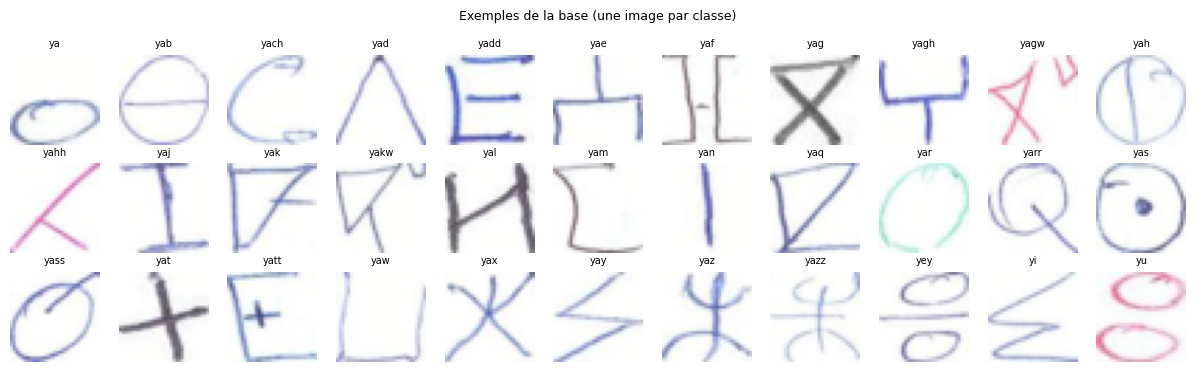

In [38]:
plot_samples(data, path=os.path.join(FIG_DIR, "samples.png"));

## 12. Architecture, vérification de la rétropropagation

Résumé du réseau (entrée 32×32×3). Le nombre de paramètres attendu est
C1 : 6·(3·5·5)+6 = 456 ; C3 : 16·(6·5·5)+16 = 2 416 ; C5 : 400·120+120 = 48 120 ;
F6 : 120·84+84 = 10 164 ; sortie : 84·33+33 = 2 805, soit **63 961**.

In [39]:
model_demo = build_lenet5(in_channels=data["in_channels"], num_classes=len(classes), seed=SEED)
summary_rows = model_demo.summary((data["in_channels"], 32, 32))

Couche    Type          Sortie              Paramètres
------------------------------------------------------
C1        Conv2D        (6, 28, 28)                456
A1        Activation    (6, 28, 28)                  0
S2        AvgPool2D     (6, 14, 14)                  0
C3        Conv2D        (16, 10, 10)             2,416
A3        Activation    (16, 10, 10)                 0
S4        AvgPool2D     (16, 5, 5)                   0
Flatten   Flatten       (400,)                       0
C5        Dense         (120,)                  48,120
A5        Activation    (120,)                       0
F6        Dense         (84,)                   10,164
A6        Activation    (84,)                        0
Output    Dense         (33,)                    2,805
------------------------------------------------------
Total                                           63,961


In [40]:
# Gradients analytiques (rétropropagation) vs numériques (différences finies), en float64
worst_tanh = gradient_check(n_checks=3)
worst_relu = gradient_check(n_checks=3, activation="relu", pool="max", c5_as_conv=True)

Paramètre         analytique     numérique   err. relative
C1.W           -1.046842e-02 -1.046842e-02        1.16e-09
C1.W            9.056195e-02  9.056195e-02        5.95e-11
C1.W            1.194050e-02  1.194050e-02        1.13e-09
C1.b           -1.884189e-02 -1.884189e-02        1.16e-10
C1.b           -1.884189e-02 -1.884189e-02        1.16e-10
C1.b           -3.588475e-02 -3.588475e-02        2.03e-10
C3.W            2.016052e-03  2.016052e-03        9.83e-10
C3.W           -1.729947e-02 -1.729947e-02        9.14e-10
C3.W           -1.119654e-02 -1.119654e-02        7.35e-10
C3.b           -1.637825e-01 -1.637825e-01        7.26e-11
C3.b           -1.446642e-01 -1.446642e-01        5.75e-12
C3.b           -7.799646e-02 -7.799646e-02        2.75e-11
C5.W           -4.841343e-03 -4.841343e-03        1.28e-09
C5.W            4.313438e-04  4.313438e-04        3.16e-09
C5.W            2.052121e-03  2.052121e-03        1.56e-09
C5.b           -4.474700e-02 -4.474700e-02        3.91e-

In [41]:
# C5 implémentée comme convolution 5x5 à 120 filtres == couche entièrement connectée sur 16@5x5
m_fc = build_lenet5(seed=3, dtype=np.float64)
m_cv = build_lenet5(seed=3, dtype=np.float64, c5_as_conv=True)
for l in ("C1", "C3", "F6", "Output"):
    for p in ("W", "b"):
        m_cv.get_layer(l).params[p][...] = m_fc.get_layer(l).params[p]
m_cv.get_layer("C5").params["W"][...] = m_fc.get_layer("C5").params["W"].T.reshape(120, 16, 5, 5)
m_cv.get_layer("C5").params["b"][...] = m_fc.get_layer("C5").params["b"]
xt = np.random.default_rng(0).normal(size=(4, 3, 32, 32))
print("max |sortie FC - sortie conv| =", np.abs(m_fc.forward(xt, False) - m_cv.forward(xt, False)).max())

max |sortie FC - sortie conv| = 3.885780586188048e-16


## 13. Modèle principal : LeNet-5 + Adam

Configuration fidèle à l'énoncé : activation tanh, pooling moyen, initialisation Xavier,
Adam (η = 10⁻³), mini-batchs de 64, sélection du meilleur modèle sur la validation.

In [42]:
reports, histories = {}, {}
model, hist, rep = run_experiment("MAIN: LeNet-5 Adam", data, "adam", 1e-3, EPOCHS, BATCH,
                                  seed=SEED, verbose=True)
reports["MAIN: LeNet-5 Adam"], histories["Adam"] = rep, hist
model.save(os.path.join(OUT_DIR, "lenet5_main_weights.npz"))

--- MAIN: LeNet-5 Adam : adam (lr=0.001), 30 époques, batch 64, 63,961 paramètres
Epoch   1/30  loss 0.5471  acc 0.8781  | val_loss 0.1508  val_acc 0.9675  | lr 0.00100  (43s)
Epoch   2/30  loss 0.1048  acc 0.9764  | val_loss 0.0720  val_acc 0.9817  | lr 0.00100  (87s)
Epoch   3/30  loss 0.0527  acc 0.9882  | val_loss 0.0458  val_acc 0.9894  | lr 0.00100  (129s)
Epoch   4/30  loss 0.0293  acc 0.9943  | val_loss 0.0377  val_acc 0.9909  | lr 0.00100  (172s)
Epoch   5/30  loss 0.0193  acc 0.9963  | val_loss 0.0225  val_acc 0.9948  | lr 0.00100  (215s)
Epoch   6/30  loss 0.0129  acc 0.9976  | val_loss 0.0252  val_acc 0.9944  | lr 0.00100  (257s)
Epoch   7/30  loss 0.0122  acc 0.9974  | val_loss 0.0292  val_acc 0.9924  | lr 0.00100  (300s)
Epoch   8/30  loss 0.0080  acc 0.9984  | val_loss 0.0188  val_acc 0.9957  | lr 0.00100  (342s)
Epoch   9/30  loss 0.0041  acc 0.9995  | val_loss 0.0153  val_acc 0.9961  | lr 0.00100  (383s)
Epoch  10/30  loss 0.0038  acc 0.9994  | val_loss 0.0133  val_acc

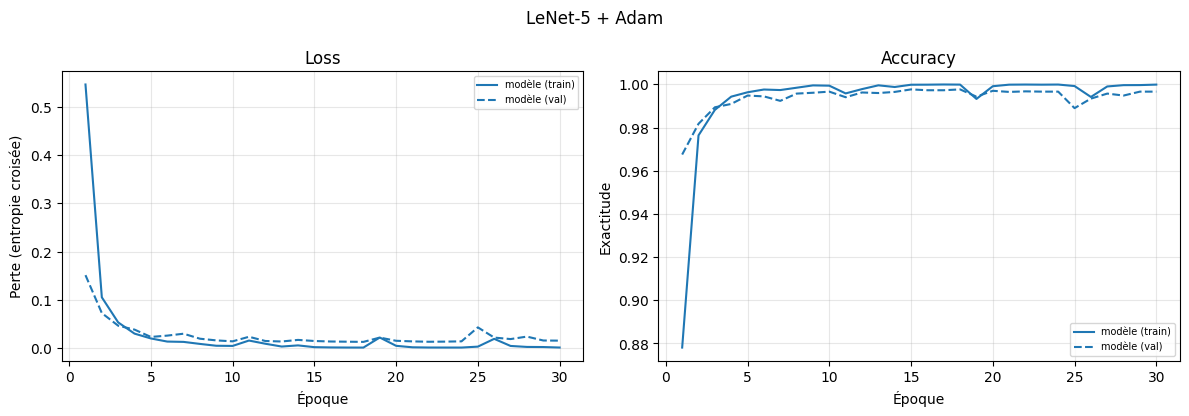

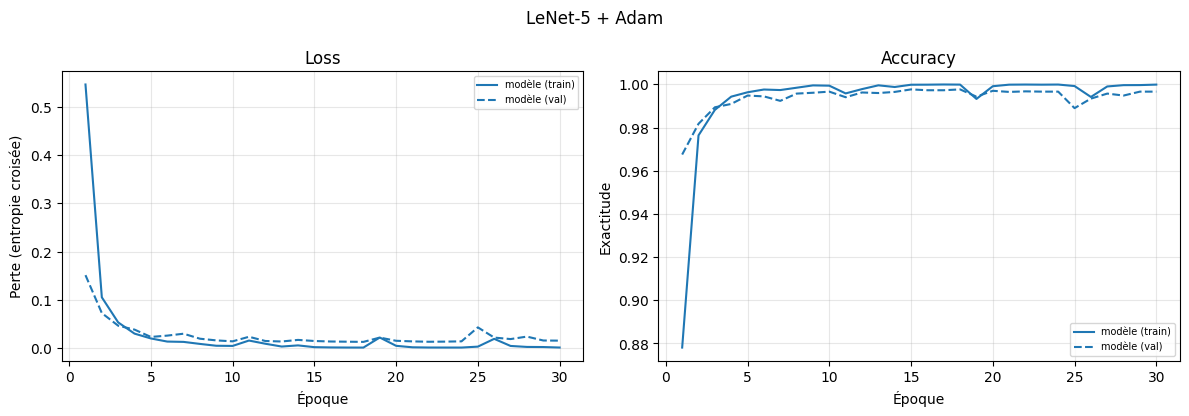

In [43]:
plot_history(hist, os.path.join(FIG_DIR, "curves_main.png"), title="LeNet-5 + Adam")

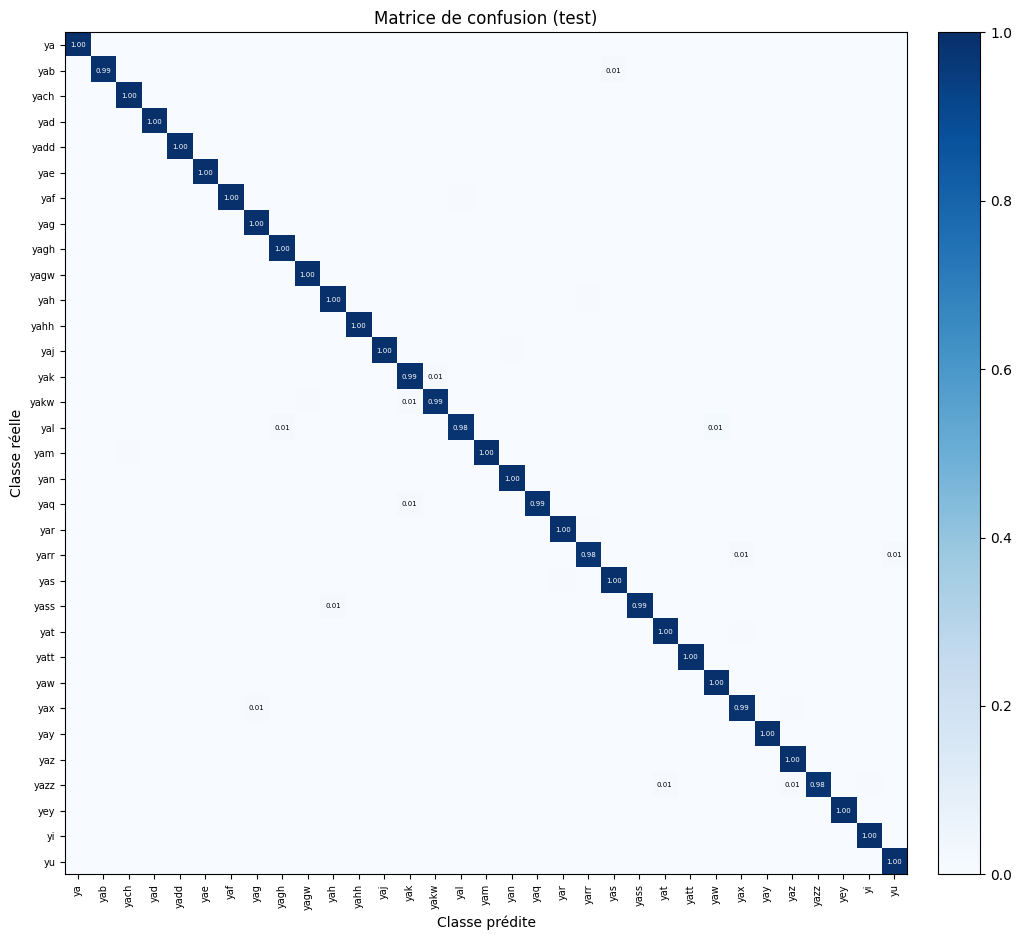

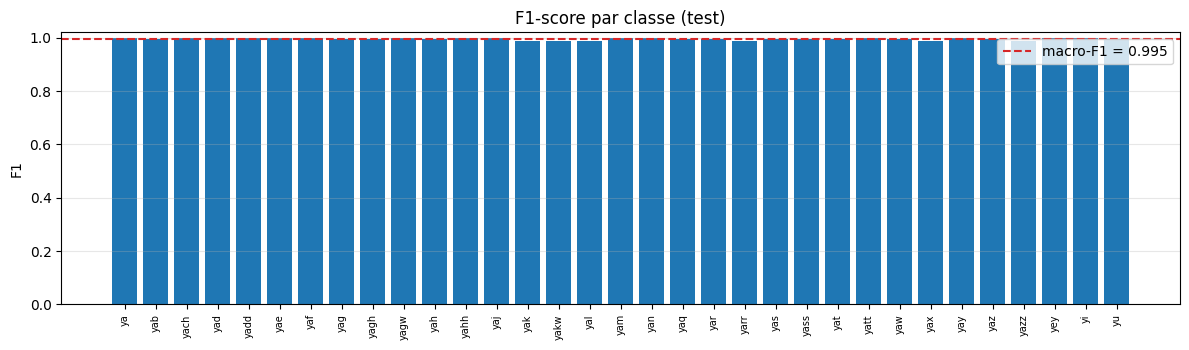

Classes les plus difficiles (F1) : [('yal', 0.987), ('yarr', 0.987), ('yax', 0.987), ('yak', 0.987), ('yazz', 0.989)]


In [44]:
cm = rep["cm"]
plot_confusion_matrix(cm, classes, normalize=True, path=os.path.join(FIG_DIR, "confusion_matrix.png"))
plot_per_class_f1(rep, classes, path=os.path.join(FIG_DIR, "per_class_f1.png"))
worst = np.argsort(rep["f1"])[:5]
print("Classes les plus difficiles (F1) :", [(classes[i], round(float(rep["f1"][i]), 3)) for i in worst])

Classe réelle : yam | prédite : yam


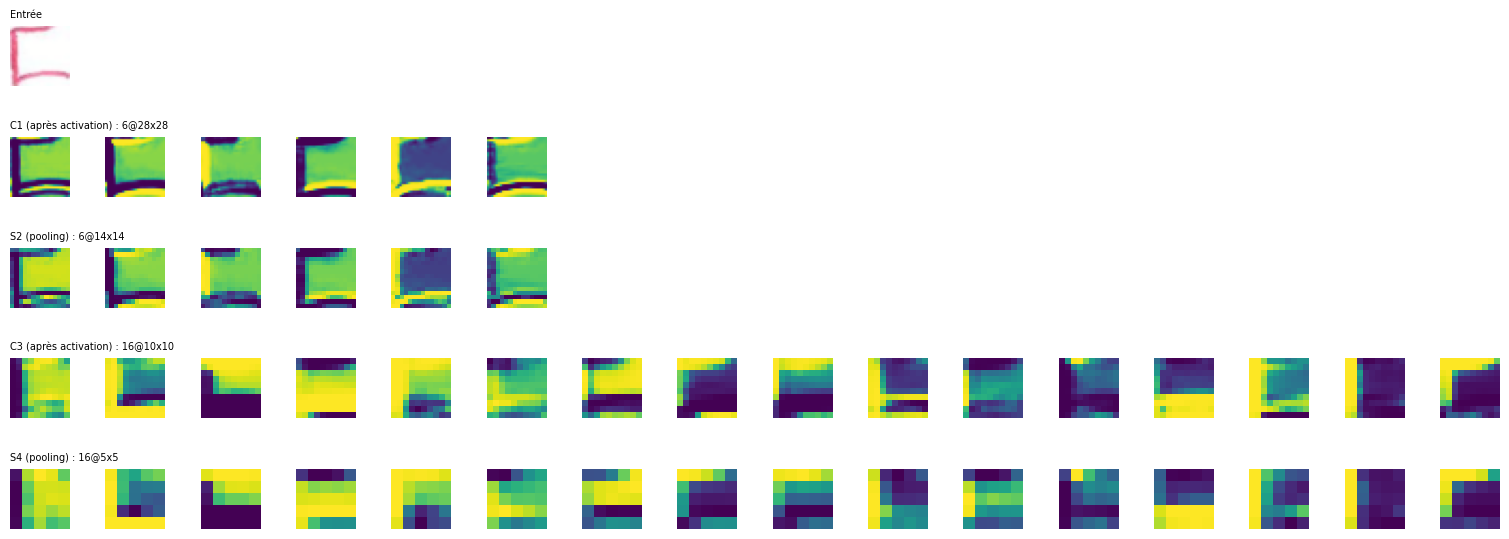

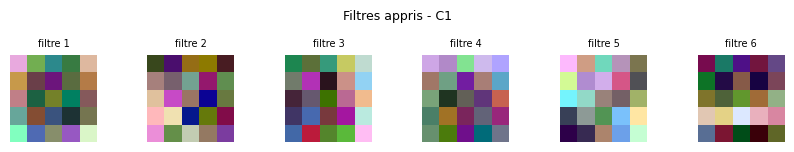

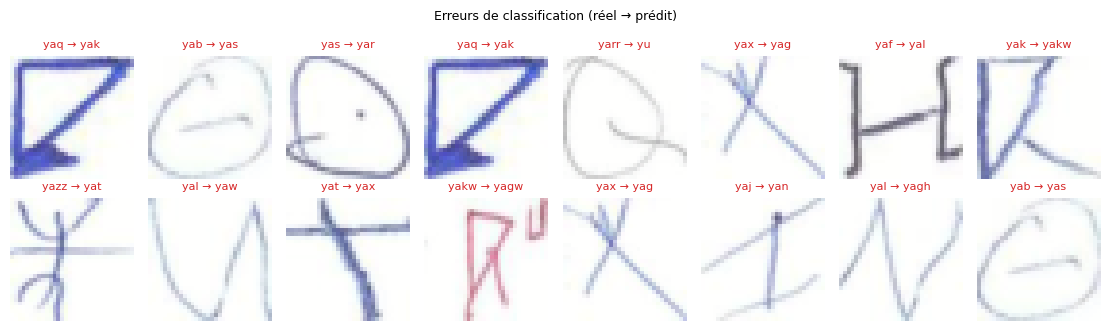

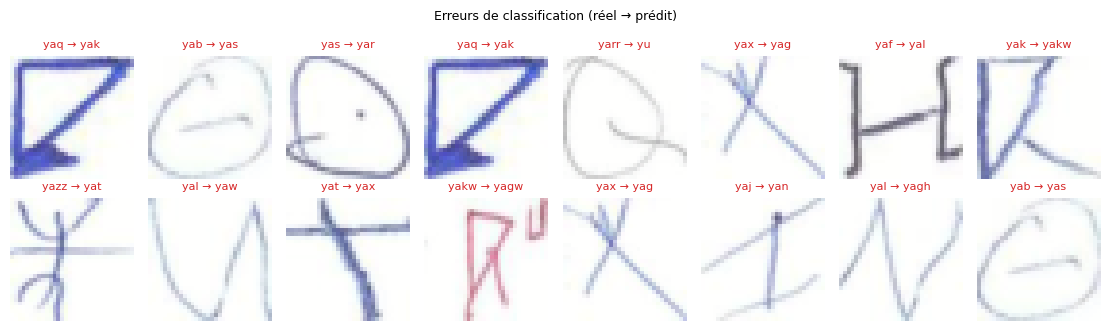

In [45]:
# Cartes de caractéristiques (une image de test) et filtres appris
x0 = data["X_test"][:1]
print("Classe réelle :", classes[data["y_test"][0]], "| prédite :", classes[int(rep["pred"][0])])
plot_feature_maps(model, x0, data["standardizer"], path=os.path.join(FIG_DIR, "feature_maps.png"))
plot_filters(model, "C1", path=os.path.join(FIG_DIR, "filters_c1.png"))
plot_misclassified(model, data, n=16, path=os.path.join(FIG_DIR, "misclassified.png"))

## 14. Comparaison des algorithmes d'optimisation

Mêmes données, même initialisation (même graine), même nombre d'époques ; seuls l'optimiseur et son pas changent.

--- OPT: SGD : sgd (lr=0.05), 30 époques, batch 64, 63,961 paramètres
[OPT: SGD] test : acc=0.9961  top-3=0.9994  macro-F1=0.9961  loss=0.0174
--- OPT: SGD + Momentum : momentum (lr=0.02), 30 époques, batch 64, 63,961 paramètres
[OPT: SGD + Momentum] test : acc=0.9968  top-3=0.9992  macro-F1=0.9968  loss=0.0103
--- OPT: SGD + Nesterov : nesterov (lr=0.02), 30 époques, batch 64, 63,961 paramètres
[OPT: SGD + Nesterov] test : acc=0.9968  top-3=0.9995  macro-F1=0.9968  loss=0.0121
--- OPT: Adagrad : adagrad (lr=0.01), 30 époques, batch 64, 63,961 paramètres
[OPT: Adagrad] test : acc=0.9953  top-3=0.9990  macro-F1=0.9953  loss=0.0235
--- OPT: RMSprop : rmsprop (lr=0.001), 30 époques, batch 64, 63,961 paramètres
[OPT: RMSprop] test : acc=0.9953  top-3=0.9988  macro-F1=0.9953  loss=0.0338
--- OPT: AdamW : adamw (lr=0.001), 30 époques, batch 64, 63,961 paramètres
[OPT: AdamW] test : acc=0.9973  top-3=0.9992  macro-F1=0.9973  loss=0.0138


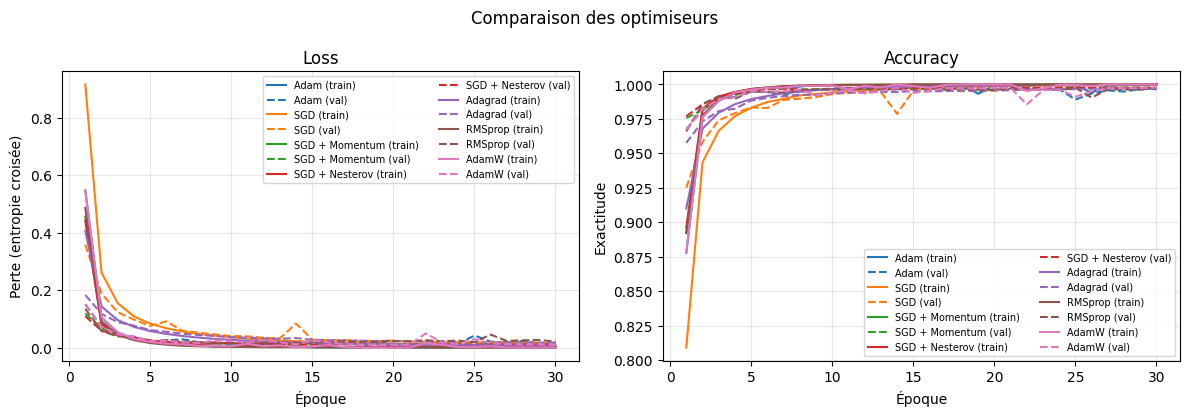

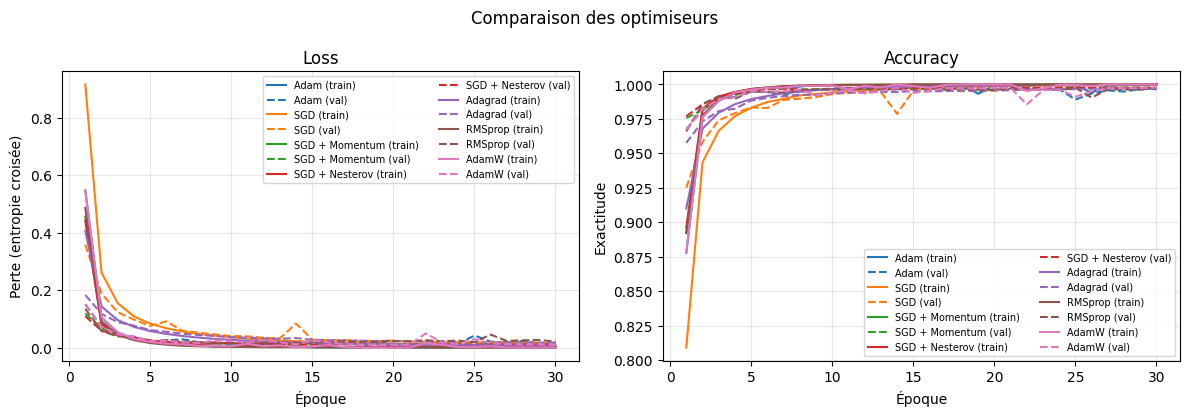

In [46]:
opt_cfg = [("SGD", "sgd", 0.05, {}),
           ("SGD + Momentum", "momentum", 0.02, {}),
           ("SGD + Nesterov", "nesterov", 0.02, {}),
           ("Adagrad", "adagrad", 0.01, {}),
           ("RMSprop", "rmsprop", 1e-3, {}),
           ("AdamW", "adamw", 1e-3, {"weight_decay": 1e-2})]
reports["OPT: Adam"] = rep
for label, name, lr, kw in opt_cfg:
    _, h, r = run_experiment(f"OPT: {label}", data, name, lr, EPOCHS, BATCH, opt_kw=kw, seed=SEED)
    reports[f"OPT: {label}"], histories[label] = r, h
plot_history(histories, os.path.join(FIG_DIR, "optimizer_curves.png"), title="Comparaison des optimiseurs")

## 15. Améliorations et ablations (bonus)

Chaque ligne modifie **un seul** élément par rapport au modèle principal (Adam, tanh, pooling moyen, Xavier).

--- ABL: ReLU + init He : adam (lr=0.001), 30 époques, batch 64, 63,961 paramètres
[ABL: ReLU + init He] test : acc=0.9959  top-3=0.9996  macro-F1=0.9959  loss=0.0210
--- ABL: tanh de LeCun (1.7159·tanh(2x/3)) : adam (lr=0.001), 30 époques, batch 64, 63,961 paramètres
[ABL: tanh de LeCun (1.7159·tanh(2x/3))] test : acc=0.9959  top-3=0.9992  macro-F1=0.9959  loss=0.0163
--- ABL: Max pooling : adam (lr=0.001), 30 époques, batch 64, 63,961 paramètres
[ABL: Max pooling] test : acc=0.9959  top-3=0.9995  macro-F1=0.9959  loss=0.0161
--- ABL: Augmentation (décalage ±2 px) : adam (lr=0.001), 30 époques, batch 64, 63,961 paramètres
[ABL: Augmentation (décalage ±2 px)] test : acc=0.9955  top-3=0.9997  macro-F1=0.9955  loss=0.0148
--- ABL: Dropout 0.3 : adam (lr=0.001), 30 époques, batch 64, 63,961 paramètres
[ABL: Dropout 0.3] test : acc=0.9961  top-3=0.9994  macro-F1=0.9961  loss=0.0158
--- ABL: Cosine lr : adam (lr=0.001), 30 époques, batch 64, 63,961 paramètres
[ABL: Cosine lr] test : acc=0.9

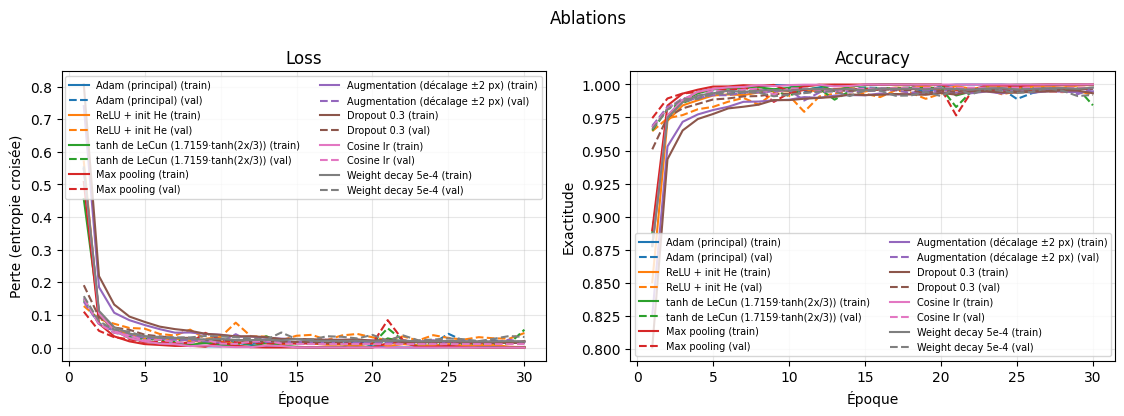

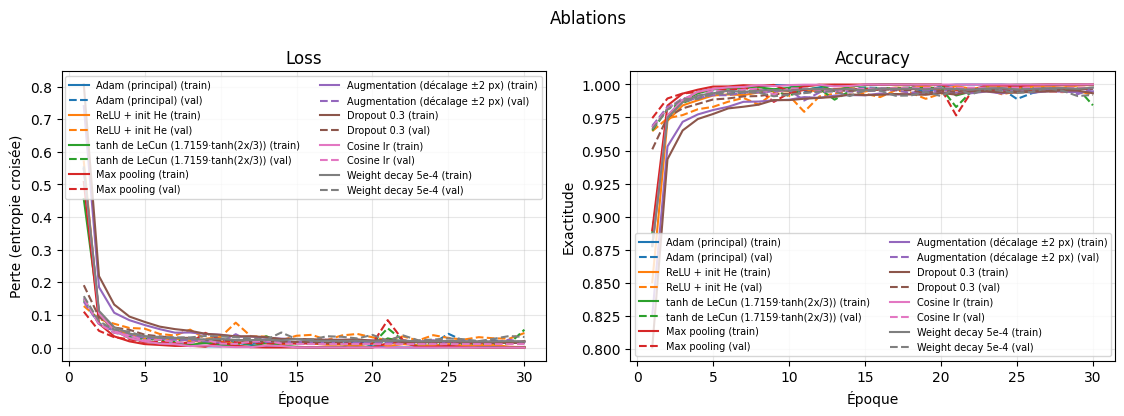

In [47]:
abl_cfg = [("ReLU + init He", dict(model_kw=dict(activation="relu", init="he"))),
           ("tanh de LeCun (1.7159·tanh(2x/3))", dict(model_kw=dict(activation="lecun_tanh"))),
           ("Max pooling", dict(model_kw=dict(pool="max"))),
           ("Augmentation (décalage ±2 px)", dict(augment=True)),
           ("Dropout 0.3", dict(model_kw=dict(dropout=0.3))),
           ("Cosine lr", dict(schedule="cosine")),
           ("Weight decay 5e-4", dict(opt_kw=dict(weight_decay=5e-4)))]
abl_hist = {"Adam (principal)": hist}
for label, kw in abl_cfg:
    _, h, r = run_experiment(f"ABL: {label}", data, "adam", 1e-3, EPOCHS, BATCH, seed=SEED, **kw)
    reports[f"ABL: {label}"], abl_hist[label] = r, h
plot_history(abl_hist, os.path.join(FIG_DIR, "ablation_curves.png"), title="Ablations")

--- ABL: Combinaison (ReLU+He, dropout, aug., cosine, wd) : adam (lr=0.001), 30 époques, batch 64, 63,961 paramètres
[ABL: Combinaison (ReLU+He, dropout, aug., cosine, wd)] test : acc=0.9966  top-3=1.0000  macro-F1=0.9966  loss=0.0125


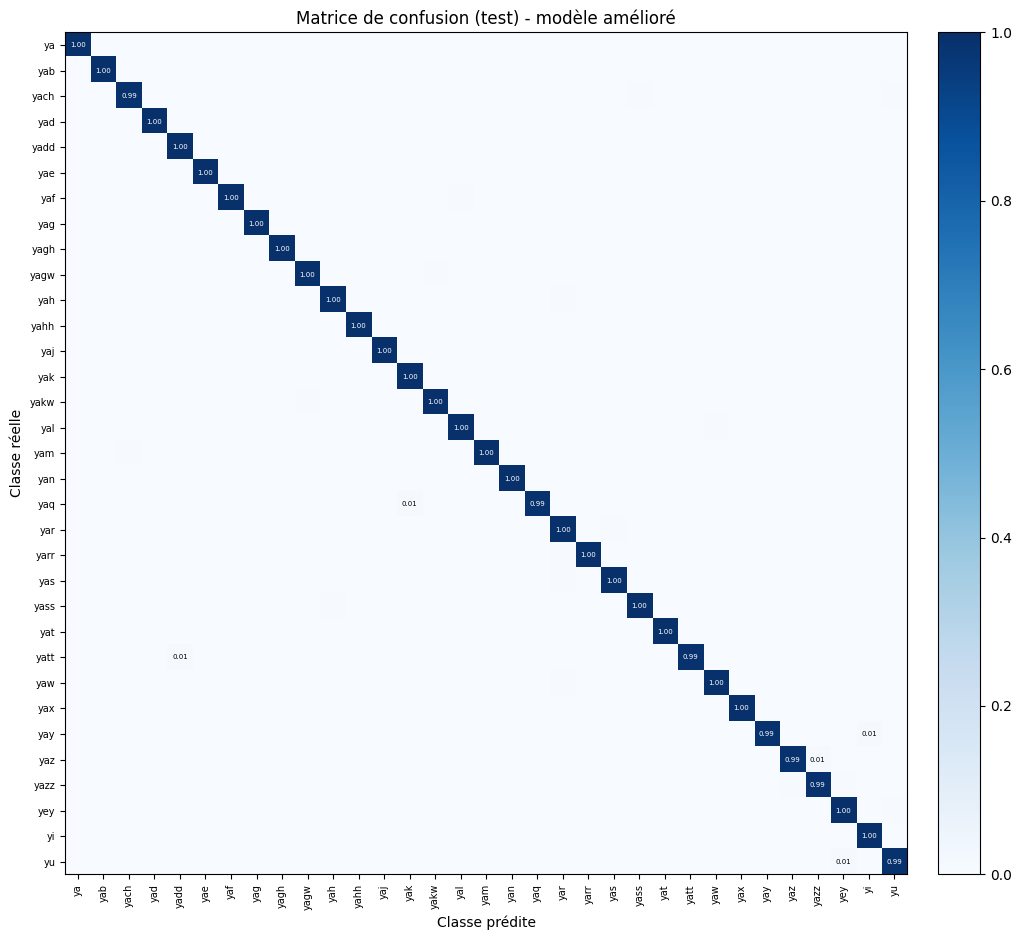

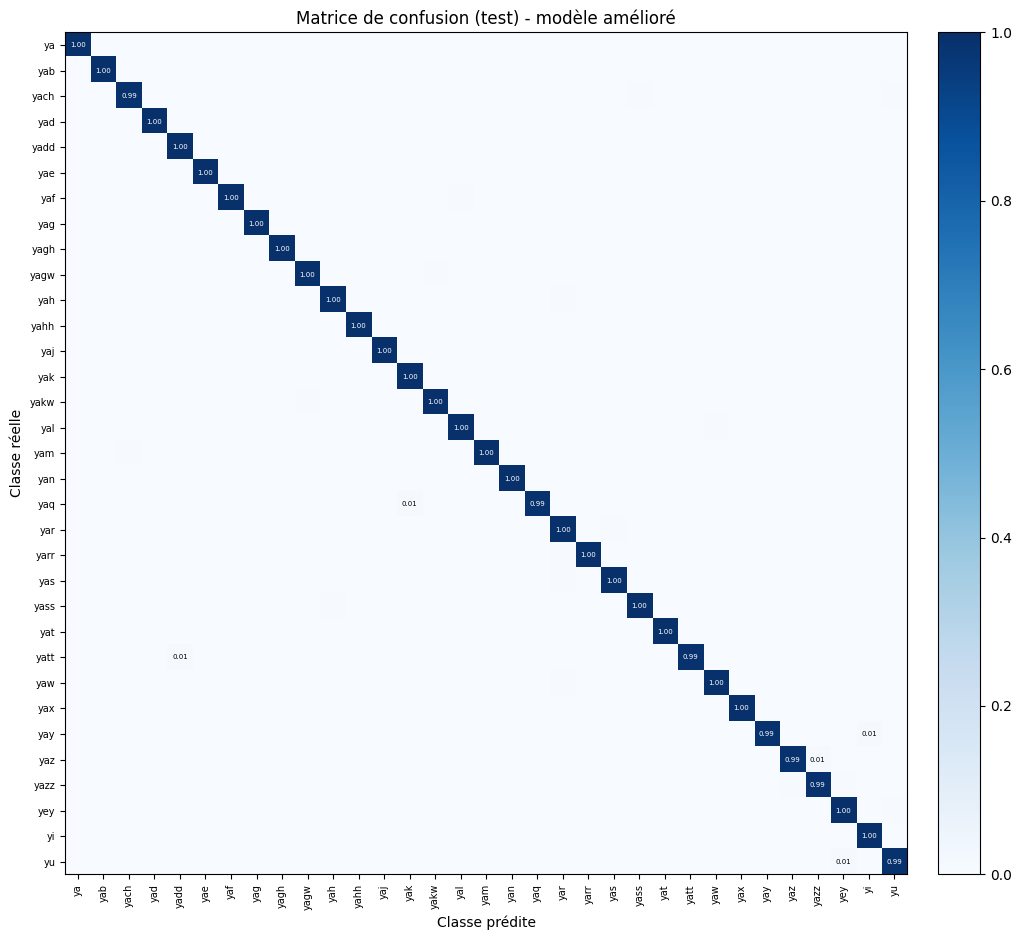

In [48]:
# Combinaison des améliorations
best_kw = dict(model_kw=dict(activation="relu", init="he", dropout=0.3), augment=True, schedule="cosine",
               opt_kw=dict(weight_decay=5e-4))
m_best, h_best, r_best = run_experiment("ABL: Combinaison (ReLU+He, dropout, aug., cosine, wd)", data,
                                        "adam", 1e-3, EPOCHS, BATCH, seed=SEED, **best_kw)
reports["ABL: Combinaison (ReLU+He, dropout, aug., cosine, wd)"] = r_best
plot_confusion_matrix(r_best["cm"], classes, path=os.path.join(FIG_DIR, "confusion_matrix_best.png"),
                      title="Matrice de confusion (test) - modèle amélioré")

## 16. Récapitulatif et export

In [49]:
import pandas as pd
tab = pd.DataFrame([{"Configuration": k, "Acc. test (%)": 100 * r["accuracy"], "Top-3 (%)": 100 * r["top3"],
                     "Macro-F1 (%)": 100 * r["macro_f1"], "Loss test": r["test_loss"],
                     "Meilleure époque": r["best_epoch"], "Temps (s)": r["train_time"]}
                    for k, r in reports.items()]).round(3)
display(tab) if "display" in globals() else print(tab.to_string())
export_results(OUT_DIR, data, reports, extra=dict(epochs=EPOCHS, batch=BATCH, seed=SEED, quick=QUICK,
                                                  gradcheck_tanh=float(worst_tanh), gradcheck_relu=float(worst_relu),
                                                  n_params=int(model.n_params())))
json.dump({k: {a: [float(x) for x in b] for a, b in h.items() if isinstance(b, list)}
           for k, h in {**histories, **{"abl:" + k: v for k, v in abl_hist.items()}}.items()},
          open(os.path.join(OUT_DIR, "histories.json"), "w"))
print(sorted(os.listdir(FIG_DIR)))

                                            Configuration  Acc. test (%)  Top-3 (%)  Macro-F1 (%)  Loss test  Meilleure époque  Temps (s)
0                                      MAIN: LeNet-5 Adam         99.547     99.883        99.546      0.018                15   1284.150
1                                               OPT: Adam         99.547     99.883        99.546      0.018                15   1284.150
2                                                OPT: SGD         99.611     99.935        99.611      0.017                29   1236.777
3                                     OPT: SGD + Momentum         99.676     99.922        99.676      0.010                28   1249.205
4                                     OPT: SGD + Nesterov         99.676     99.948        99.676      0.012                15   1242.837
5                                            OPT: Adagrad         99.534     99.896        99.534      0.024                27   1264.815
6                                 

In [50]:
# télécharger tous les résultats (figures, tableaux .tex, poids) en une archive
try:
    from google.colab import files
    import shutil
    shutil.make_archive("outputs_amhcd", "zip", OUT_DIR)
    files.download("outputs_amhcd.zip")
except ImportError:
    print("Hors Colab : les résultats sont dans", OUT_DIR)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>